# 01. Bayesian price elasticity

Weekly unit sales for a catalogue of SKUs. The decision is not "the elasticity is -1.4". It is: if we raise this SKU's price by 10%, what happens to revenue, and how sure are we?

## Business use

Dynamic pricing needs a demand curve per SKU. Thin SKUs should borrow strength from the category instead of getting a wild elasticity of their own. The quantity we hand to pricing is a distribution of revenue change, plus the probability that revenue goes up.

## Intuition

Write down how the data could have been generated, put distributions on the unknowns, and let the data update them. The posterior is a cloud of plausible parameter values. Revenue, optimal price, and "should we raise it?" are computed draw by draw, so the uncertainty comes with the answer.

## Model

$$
p(\theta \mid y) \propto p(y \mid \theta)\, p(\theta)
$$

$$
\text{units}_i \sim \mathrm{Poisson}(\lambda_i), \quad
\log \lambda_i = \alpha_{s(i)} + \beta_{s(i)} \log(p_i / \bar p_{s(i)})
$$

$$
\beta_s = \mu_\beta + \sigma_\beta \, z_s, \quad z_s \sim \mathrm{Normal}(0, 1)
$$

With a log-log curve, a price factor $r$ multiplies revenue by $r^{1+\beta}$. A +10% price raises revenue only when $\beta > -1$. Partial pooling shrinks noisy SKUs toward the category mean $\mu_\beta$ by an amount the data chooses through $\sigma_\beta$.

| Parameter | Prior | Role |
|---|---|---|
| $\mu_\beta$ | Normal(-1, 0.5) | Category elasticity. Centred on "demand slopes down". |
| $\sigma_\beta$ | HalfNormal(0.5) | How much SKUs differ. |
| $z_s$ | Normal(0, 1) | Non-centred SKU residual. |
| $\alpha_s$ | Normal(3, 1.5) | Log baseline weekly demand. |
| units | Poisson | Weekly counts. |

Price is centred at each SKU's base price, so $\alpha_s$ is demand at the usual price and $\beta_s$ is the elasticity.


## Step 1. Simulate a category

Eight SKUs, 52 weeks, Poisson counts, fixed seed. Elasticities are drawn from Normal(-1.4, 0.35). Prices wobble by about 15% so the slope is identified. This is simulated data: we print shapes and a few aggregates, not a dump of every row.


In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pymc as pm
from IPython.display import display

rng = np.random.default_rng(42)
n_sku, n_weeks = 8, 52
true_mu_beta, true_sigma_beta = -1.4, 0.35
beta_sku = rng.normal(true_mu_beta, true_sigma_beta, n_sku)
alpha_sku = rng.normal(4.0, 0.5, n_sku)
base_price = rng.uniform(10, 60, n_sku)
sku = np.repeat(np.arange(n_sku), n_weeks)
price = base_price[sku] * np.exp(rng.normal(0, 0.15, sku.size))
log_p = np.log(price / base_price[sku])
units = rng.poisson(np.exp(alpha_sku[sku] + beta_sku[sku] * log_p))
coords = {"sku": [f"SKU{i}" for i in range(n_sku)]}

print("rows:", int(units.size), "SKUs:", n_sku, "weeks:", n_weeks)
print("true beta:", np.round(beta_sku, 2))
print(
    "units mean/sd/max/share_zero:",
    round(float(units.mean()), 2),
    round(float(units.std()), 2),
    int(units.max()),
    round(float(np.mean(units == 0)), 3),
)

rows: 416 SKUs: 8 weeks: 52
true beta: [-1.29 -1.76 -1.14 -1.07 -2.08 -1.86 -1.36 -1.51]
units mean/sd/max/share_zero: 65.46 27.49 192 0.0


## Step 2. Prior predictive check

Sample from the prior, before looking at how well the posterior fits, and check that weekly units land in a plausible range: not all zeros, and not millions. A flat prior on a log-scale intercept often fails this check.


In [2]:
with pm.Model(coords=coords):
    log_p_data = pm.Data("log_p", log_p)
    sku_idx = pm.Data("sku_idx", sku)
    mu_beta = pm.Normal("mu_beta", -1.0, 0.5)
    sigma_beta = pm.HalfNormal("sigma_beta", 0.5)
    z = pm.Normal("z", 0, 1, dims="sku")
    beta = pm.Deterministic("beta", mu_beta + sigma_beta * z, dims="sku")
    alpha = pm.Normal("alpha", 3.0, 1.5, dims="sku")
    lam = pm.math.exp(alpha[sku_idx] + beta[sku_idx] * log_p_data)
    pm.Poisson("units", lam, observed=units, shape=log_p_data.shape)
    prior = pm.sample_prior_predictive(500, random_seed=1)

prior_units = np.asarray(prior["prior_predictive"]["units"]).reshape(-1)
p05, p50, p95 = np.quantile(prior_units, [0.05, 0.5, 0.95])
print(f"prior predictive weekly units: p05={p05:.1f} median={p50:.1f} p95={p95:.1f}")

Sampling: [alpha, mu_beta, sigma_beta, units, z]


prior predictive weekly units: p05=1.0 median=20.0 p95=239.0


## Step 3. The sampler, twice

The hierarchy is non-centred from the start: $\beta_s = \mu_\beta + \sigma_\beta z_s$. That is the form that avoids the funnel, where a centred $\beta_s \sim \mathrm{Normal}(\mu_\beta, \sigma_\beta)$ makes $\sigma_\beta$ and the SKU offsets fight each other.

First fit: sampler defaults (`target_accept=0.8`, 1,000 tuning steps). Second fit: the settings we would ship (`target_accept=0.95`, 2,000 tuning steps). Four chains, 1,000 draws, seed 1.

A reference run of this same default fit reported **18 divergences**, R-hat 1.01 and an ESS around 250 for $\mu_\beta$. Count whatever this machine reports. A clean default run is not a reason to skip the gate. The higher `target_accept` is the conservative setting.


In [3]:
def sample_elasticity(target_accept: float, tune: int, draws: int, seed: int):
    with pm.Model(coords=coords) as model:
        log_p_data = pm.Data("log_p", log_p)
        sku_idx = pm.Data("sku_idx", sku)
        mu_beta = pm.Normal("mu_beta", -1.0, 0.5)
        sigma_beta = pm.HalfNormal("sigma_beta", 0.5)
        z = pm.Normal("z", 0, 1, dims="sku")
        beta = pm.Deterministic("beta", mu_beta + sigma_beta * z, dims="sku")
        alpha = pm.Normal("alpha", 3.0, 1.5, dims="sku")
        lam = pm.math.exp(alpha[sku_idx] + beta[sku_idx] * log_p_data)
        pm.Poisson("units", lam, observed=units, shape=log_p_data.shape)
        idata = pm.sample(
            draws,
            tune=tune,
            chains=4,
            cores=2,
            target_accept=target_accept,
            random_seed=seed,
            progressbar=False,
        )
    return model, idata


model_default, idata_default = sample_elasticity(0.8, tune=1000, draws=1000, seed=1)
n_div_default = int(np.asarray(idata_default.sample_stats["diverging"]).sum())
print("default settings, divergences:", n_div_default)
print(az.summary(idata_default, var_names=["mu_beta", "sigma_beta"]).to_string())

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 2 jobs)


NUTS: [mu_beta, sigma_beta, z, alpha]


Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 3 seconds.


default settings, divergences: 0
             mean     sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
mu_beta     -1.45  0.175     -1.7     -1.2      966     1415  1.00    0.0056  0.0035
sigma_beta  0.497  0.137     0.32     0.74     1465     1898  1.00    0.0036  0.0029


In [4]:
model, idata = sample_elasticity(0.95, tune=2000, draws=1000, seed=1)
n_div = int(np.asarray(idata.sample_stats["diverging"]).sum())
summary = az.summary(idata, var_names=["mu_beta", "sigma_beta", "beta"])
print("shipped settings, divergences:", n_div)
print(summary.to_string())
assert n_div == 0
assert float(summary["r_hat"].astype(float).max()) < 1.01
assert float(summary["ess_bulk"].astype(float).min()) > 400

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 2 jobs)


NUTS: [mu_beta, sigma_beta, z, alpha]


Sampling 4 chains for 2_000 tune and 1_000 draw iterations (8_000 + 4_000 draws total) took 8 seconds.


shipped settings, divergences: 0
              mean     sd eti89_lb eti89_ub ess_bulk ess_tail r_hat mcse_mean mcse_sd
mu_beta      -1.45  0.177     -1.7     -1.2     1227     1563  1.00    0.0051  0.0037
sigma_beta   0.494   0.14     0.32     0.75     1680     2141  1.00    0.0032  0.0028
beta[SKU0]  -1.255  0.161     -1.5       -1     5726     3378  1.00    0.0021  0.0028
beta[SKU1]   -1.58  0.177     -1.9     -1.3     5292     3608  1.00    0.0024  0.0026
beta[SKU2]  -1.027  0.103     -1.2    -0.87     4834     3457  1.00    0.0015  0.0014
beta[SKU3]  -1.055  0.107     -1.2    -0.88     4922     3457  1.00    0.0015  0.0015
beta[SKU4]  -2.328  0.123     -2.5     -2.1     4385     3090  1.00    0.0019  0.0016
beta[SKU5]  -1.874  0.092       -2     -1.7     4907     3145  1.00    0.0013  0.0014
beta[SKU6]   -1.36  0.103     -1.5     -1.2     5400     3249  1.00    0.0014  0.0015
beta[SKU7]  -1.577   0.15     -1.8     -1.3     5165     3297  1.00    0.0021  0.0022


## Step 4. Posterior predictive check

Replicate the whole dataset from posterior draws and compare summaries the decision depends on: mean, spread, and the maximum week. The Bayesian p-value is the share of replicates whose statistic is at least as large as the data. Values near 0.5 mean the data looks typical. Values near 0 or 1 mean that statistic is hard for the model to produce.

The share of zero-unit weeks is often uninformative here: if nobody has a zero week, every replicate can also have no zeros and the p-value sits at 1. That is an uninformative statistic, not by itself a misfit. Pick statistics the decision uses.


In [5]:
with model:
    ppc = pm.sample_posterior_predictive(idata, random_seed=1, progressbar=False)
replicated = np.asarray(ppc["posterior_predictive"]["units"]).reshape(-1, units.size)


def share_zero(values: np.ndarray) -> float:
    return float(np.mean(values == 0))


for name, fn in [("mean", np.mean), ("sd", np.std), ("share_zero", share_zero), ("max", np.max)]:
    observed = float(fn(units))
    rep_stats = np.array([fn(row) for row in replicated[:2000]])
    lo, hi = np.quantile(rep_stats, [0.05, 0.95])
    bayes_p = float(np.mean(rep_stats >= observed))
    print(f"PPC {name}: observed={observed:.2f} replicated 90%=({lo:.2f},{hi:.2f}) bayes_p={bayes_p:.2f}")

Sampling: [units]


PPC mean: observed=65.46 replicated 90%=(64.50,66.36) bayes_p=0.47
PPC sd: observed=27.49 replicated 90%=(26.44,28.53) bayes_p=0.47
PPC share_zero: observed=0.00 replicated 90%=(0.00,0.00) bayes_p=1.00
PPC max: observed=192.00 replicated 90%=(173.00,223.00) bayes_p=0.62


## Step 5. The decision: +10% price

For each posterior draw, units scale by $1.1^{\beta}$ and revenue by $1.1^{1+\beta}$. Report the median revenue change, a 90% interval, and $P(\text{revenue up})$.


SKU0: units change -11.3%  revenue change median -2.4% 90%CI (-4.8%,+0.1%) P(rev up)=0.06
SKU1: units change -14.0%  revenue change median -5.4% 90%CI (-8.0%,-2.7%) P(rev up)=0.00
SKU2: units change -9.3%  revenue change median -0.3% 90%CI (-1.9%,+1.3%) P(rev up)=0.40
SKU3: units change -9.6%  revenue change median -0.5% 90%CI (-2.2%,+1.2%) P(rev up)=0.30
SKU4: units change -19.9%  revenue change median -11.9% 90%CI (-13.6%,-10.2%) P(rev up)=0.00
SKU5: units change -16.4%  revenue change median -8.0% 90%CI (-9.3%,-6.7%) P(rev up)=0.00
SKU6: units change -12.2%  revenue change median -3.4% 90%CI (-4.9%,-1.8%) P(rev up)=0.00
SKU7: units change -13.9%  revenue change median -5.4% 90%CI (-7.5%,-3.1%) P(rev up)=0.00


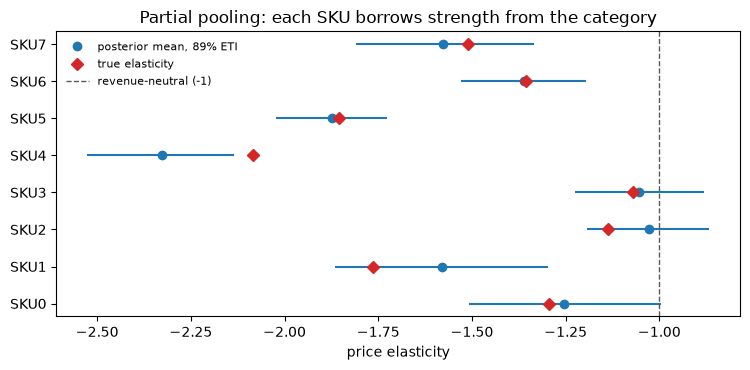

In [6]:
beta_draws = np.asarray(idata["posterior"]["beta"]).reshape(-1, n_sku)
revenue_ratio = 1.1 ** (1 + beta_draws)
decisions = []
for i in range(n_sku):
    revenue_change = revenue_ratio[:, i] - 1
    decision = {
        "sku": f"SKU{i}",
        "true_beta": float(beta_sku[i]),
        "post_mean": float(beta_draws[:, i].mean()),
        "units_change": float(np.mean(1.1 ** beta_draws[:, i] - 1)),
        "rev_median": float(np.median(revenue_change)),
        "rev_lo": float(np.quantile(revenue_change, 0.05)),
        "rev_hi": float(np.quantile(revenue_change, 0.95)),
        "p_rev_up": float(np.mean(revenue_ratio[:, i] > 1)),
    }
    decisions.append(decision)
    print(
        f"{decision['sku']}: units change {decision['units_change']:+.1%}  "
        f"revenue change median {decision['rev_median']:+.1%} "
        f"90%CI ({decision['rev_lo']:+.1%},{decision['rev_hi']:+.1%}) "
        f"P(rev up)={decision['p_rev_up']:.2f}"
    )

beta_rows = summary.loc[summary.index.astype(str).str.startswith("beta")]
means = beta_rows["mean"].to_numpy()
lo = beta_rows["eti89_lb"].to_numpy()
hi = beta_rows["eti89_ub"].to_numpy()
fig, ax = plt.subplots(figsize=(7.6, 3.8))
y = np.arange(n_sku)
ax.hlines(y, lo, hi, color="C0")
ax.plot(means, y, "o", color="C0", label="posterior mean, 89% ETI")
ax.plot(beta_sku, y, "D", color="C3", label="true elasticity")
ax.axvline(-1.0, color="0.35", ls="--", lw=1, label="revenue-neutral (-1)")
ax.set_yticks(y, coords["sku"])
ax.set_xlabel("price elasticity")
ax.set_title("Partial pooling: each SKU borrows strength from the category")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
display(fig)
plt.close(fig)

## What a divergence looks like

On the 52-week series the non-centred model is well identified, so the default sampler may already look healthy. The failure mode shows up when groups are thin and the hierarchy is centred, with a vague scale prior. The next cell is that stress test, and it is not the pricing model: 8 SKUs, 4 weeks, little price variation, $\beta_s \sim \mathrm{Normal}(\mu_\beta, \sigma_\beta)$ with a Half-Cauchy scale. The same cell then refits the thin data non-centred with `target_accept=0.99`. Divergences should fall from dozens to a handful, often to zero. A leftover divergence means the geometry is still awkward, not that the check was skipped.

Divergences mean the numerical integrator blew up, usually in a high-curvature neck. Those regions are under-explored, so the posterior can be biased even if R-hat looks close to 1. Fixes, in the order we use them: non-centred parameterisation, higher `target_accept` (0.9 to 0.99), more informative or better-scaled priors.


In [7]:
def sample_thin(centred: bool, target_accept: float, tune: int):
    thin_rng = np.random.default_rng(42)
    n_group, n_obs = 8, 4
    thin_beta = thin_rng.normal(-1.4, 0.35, n_group)
    thin_alpha = thin_rng.normal(4.0, 0.5, n_group)
    thin_sku = np.repeat(np.arange(n_group), n_obs)
    thin_log_p = thin_rng.normal(0, 0.08, thin_sku.size)
    thin_units = thin_rng.poisson(np.exp(thin_alpha[thin_sku] + thin_beta[thin_sku] * thin_log_p))
    with pm.Model(coords={"sku": [f"SKU{i}" for i in range(n_group)]}):
        mu_beta = pm.Normal("mu_beta", 0.0, 5.0)
        sigma_beta = pm.HalfCauchy("sigma_beta", beta=5.0)
        if centred:
            beta = pm.Normal("beta", mu_beta, sigma_beta, dims="sku")
        else:
            z = pm.Normal("z", 0, 1, dims="sku")
            beta = pm.Deterministic("beta", mu_beta + sigma_beta * z, dims="sku")
        alpha = pm.Normal("alpha", 0.0, 5.0, dims="sku")
        lam = pm.math.exp(alpha[thin_sku] + beta[thin_sku] * thin_log_p)
        pm.Poisson("units", lam, observed=thin_units)
        thin_idata = pm.sample(
            400,
            tune=tune,
            chains=4,
            cores=2,
            target_accept=target_accept,
            random_seed=1,
            progressbar=False,
        )
    return int(np.asarray(thin_idata.sample_stats["diverging"]).sum())


div_centred = sample_thin(centred=True, target_accept=0.8, tune=400)
div_noncentred = sample_thin(centred=False, target_accept=0.99, tune=1200)
print("thin centred hierarchy, divergences:", div_centred)
print("thin non-centred, target_accept=0.99, divergences:", div_noncentred)
assert div_centred >= 10
assert div_noncentred <= 2

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 2 jobs)


NUTS: [mu_beta, sigma_beta, beta, alpha]


/workspace/bayesian-modelling/.venv/lib/python3.12/site-packages/pymc/step_methods/hmc/quadpotential.py:321: RuntimeWarning: overflow encountered in dot
  return 0.5 * np.dot(x, v_out)


Sampling 4 chains for 400 tune and 400 draw iterations (1_600 + 1_600 draws total) took 3 seconds.


There were 31 divergences after tuning. Increase `target_accept` or reparameterize.


... (3 outputs left out)

Multiprocess sampling (4 chains in 2 jobs)


NUTS: [mu_beta, sigma_beta, z, alpha]


Sampling 4 chains for 1_200 tune and 400 draw iterations (4_800 + 1_600 draws total) took 4 seconds.


thin centred hierarchy, divergences: 31
thin non-centred, target_accept=0.99, divergences: 0


## How to read the outputs

| Output | Meaning | Healthy result |
|---|---|---|
| `mean`, `sd` | Posterior mean and standard deviation | In a simulation, within about 2 sd of the truth |
| `eti89_lb`, `eti89_ub` | 89% equal-tailed credible interval (ArviZ 1 default) | Narrow enough that the decision does not flip inside it |
| `hdi_3%`, `hdi_97%` | 94% highest-density interval on older ArviZ | Same reading, different default |
| `ess_bulk`, `ess_tail` | Effective draws for the centre and the tails | Above about 400 in total |
| `r_hat` | Between-chain vs within-chain agreement | 1.00, and below 1.01 |
| `mcse_mean` | Monte Carlo error of the mean | Small relative to the precision you quote |
| PPC Bayesian p-value | How typical the observed statistic is | Away from 0 and 1 |
| divergences | NUTS trajectories that blew up | 0 |

The revenue line is the decision. An SKU whose 90% interval on revenue change lies entirely below zero should not get the price rise. An SKU whose interval covers zero, with $P(\text{revenue up})$ near one half, is where an experiment is worth the traffic.

A reference execution of the shipped sampler (1,000 draws, tune 2,000, `target_accept=0.95`) recovered $\mu_\beta$ near -1.45 with R-hat 1.00, ESS in the thousands, zero divergences, and PPC Bayesian p-values for the mean and sd near 0.5. Read the table above the same way if your seeds move the third digit.

## Pitfalls

- Flat priors on log-scale parameters imply absurd demand. Run the prior predictive.
- Centred hierarchies with few observations per group produce divergences. The thin-data cell is that case.
- A credible interval on $\beta$ is not a predictive interval on next week's units.
- Prices set in response to demand bias the elasticity. Prefer experiments, promotions, or controls.
- Optimising revenue when the business cares about margin, or deciding at the posterior mean only.


## How to explain this to a CTO

Lead with the SKU, the action, and the chance the action makes money. Leave R-hat out of the sentence.


In [8]:
most_elastic = min(decisions, key=lambda row: row["post_mean"])
coin_flip = min(decisions, key=lambda row: abs(row["p_rev_up"] - 0.5))


def pct(value: float) -> str:
    return f"{value:+.0%}"


print(
    f"For {most_elastic['sku']}, a 10% price rise changes revenue by about "
    f"{pct(most_elastic['rev_median'])} "
    f"(90% of the plausible range is {pct(most_elastic['rev_lo'])} to {pct(most_elastic['rev_hi'])}). "
    f"The chance revenue goes up is {most_elastic['p_rev_up']:.0%}. Do not raise that price."
)
print(
    f"For {coin_flip['sku']}, the chance a 10% rise increases revenue is "
    f"{coin_flip['p_rev_up']:.0%}, and the 90% range is "
    f"{pct(coin_flip['rev_lo'])} to {pct(coin_flip['rev_hi'])}. "
    "That is close enough to a coin flip that a price test is worth the traffic before a rollout."
)

For SKU4, a 10% price rise changes revenue by about -12% (90% of the plausible range is -14% to -10%). The chance revenue goes up is 0%. Do not raise that price.
For SKU2, the chance a 10% rise increases revenue is 40%, and the 90% range is -2% to +1%. That is close enough to a coin flip that a price test is worth the traffic before a rollout.


## Check yourself

**How do you choose priors when someone calls them subjective?**
Put them on a scale a merchant understands (elasticity near -1 to -2, demand falls when price rises), show the prior predictive, and refit with a wider prior. If the decision does not change, say so. Where the data is thin, the prior is the documented assumption that replaces a silent one.

**When would you not use MCMC for this?**
A conjugate Beta-Binomial conversion rate (notebook 05) has a closed form. A huge dataset whose posterior is essentially a point can use MAP plus a Laplace approximation. MCMC is for offline fits where the curve has no closed form and the decision needs a calibrated probability.
